# Analysis-ready output from `arrayprobe`

`arrayprobe` writes **NETCDF3_CLASSIC**, because that is what MATLAB's bare `'clobber'`
default writes and the port's whole claim is that its output is byte-comparable with the
original's. That format is a poor fit for analysis: a variable is stored *contiguously*, so
pulling one second out of a twenty-million-particle file means seeking through the whole
variable, and nothing is compressed.

`arco_export` resolves that without touching the fidelity claim. It lives in the
**enhancements** package, reads a faithful output file, and writes a derived analysis-ready
copy. **The source file is never opened for writing.**

This notebook runs the export on a small file and shows what it decided and why. It needs
no campaign data — it builds its own input if you do not have one.

**Before this:** [06_read_products](../1_getting_started/06_read_products.ipynb) (Reading the output files). **Related:** [04_output_formats_and_tables](04_output_formats_and_tables.ipynb). **Needs:** the enhancements package and `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/7_analysis_and_outputs/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )


Import the export function and its helpers, and print the default chunk size and compression level. These two settings decide how the exported variables are laid out on disk.

In [2]:
from pathlib import Path

import netCDF4
import numpy as np

from arrayprobe_enhancements.arco_export import (
    DEFAULT_CHUNK,
    DEFAULT_COMPLEVEL,
    export,
    plan_variable,
)

print(f"chunk = {DEFAULT_CHUNK:,} particles, zlib level = {DEFAULT_COMPLEVEL}")

chunk = 200,000 particles, zlib level = 4


## An input to work on

Point `SOURCE` at any `proc.*.nc` or `sd.*.nc` the port has written. If you have none, the
next cell writes a small stand-in with the shape that matters: every variable declared
`double`, which is what archived UIOOPS products from a field campaign do regardless of what a variable
actually holds. That declaration is why narrowing pays here, and why it has to be decided
from the *values* rather than from the declared type.

`SOURCE` is a relative path, so the stand-in is written to `proc_example.nc` at the package root, the working directory this notebook is launched from.

In [3]:
SOURCE = Path("proc_example.nc")  # <- change to a real port output if you have one

if not SOURCE.is_file():
    rng = np.random.default_rng(0)
    n = 200_000
    with netCDF4.Dataset(SOURCE, "w", format="NETCDF3_CLASSIC") as ds:
        ds.createDimension("particle", n)
        # Integral counts, held as double -- the narrowing case.
        v = ds.createVariable("image_length", "f8", ("particle",))
        v[:] = rng.integers(1, 400, n).astype(float)
        # A genuine float -- must stay float64, and shuffle will HURT it.
        v = ds.createVariable("image_diam_minR", "f8", ("particle",))
        v[:] = rng.gamma(2.0, 30.0, n)
        # Integral but carrying NaN -- deliberately NOT narrowed.
        v = ds.createVariable("particle_time", "f8", ("particle",))
        vals = rng.integers(0, 86_400, n).astype(float)
        vals[rng.random(n) < 0.01] = np.nan
        v[:] = vals
    print(f"wrote a stand-in: {SOURCE} ({SOURCE.stat().st_size / 1e6:.1f} MB)")
else:
    print(f"using {SOURCE} ({SOURCE.stat().st_size / 1e6:.1f} MB)")

using proc_example.nc (4.8 MB)


## What it decides, before it writes anything

`plan_variable` reads a variable's **actual values** and returns the dtype it will use, whether
the shuffle filter helps, whether the result is lossless, and the reason. Ask it directly —
the plan is not a side effect you have to infer from the output file.

In [4]:
with netCDF4.Dataset(SOURCE) as ds:
    for name, var in ds.variables.items():
        plan = plan_variable(name, np.asarray(var[:]).ravel())
        print(f"{name:20s} -> {plan.dtype:3s}  shuffle={str(plan.shuffle):5s}  "
              f"lossless={str(plan.lossless):5s}")
        print(f"{'':20s}    {plan.reason}")

image_length         -> i2   shuffle=True   lossless=True 
                        every value integral in [1, 399]; i2 holds them exactly
image_diam_minR      -> f8   shuffle=False  lossless=True 
                        float64 kept; shuffle measured to HURT float data here
particle_time        -> f8   shuffle=False  lossless=True 
                        integral but carries NaN; an integer type would need a fill value that changes the data


Three decisions worth reading closely, because two of them are counter-intuitive.

**`image_length` narrows to an integer type.** Every value is integral and the range fits, so
the narrowing is *lossless by construction* — and it is checked per variable rather than
trusted from the declaration, which says `double` for everything.

**`image_diam_minR` keeps `float64` and turns shuffle OFF.** Shuffle groups
same-significance bytes before compression. Measured on real port output it gives
**8.6 %** of baseline with shuffle against 10.7 % without for an integral variable — but
**46.4 % with against 24.9 % without** for a float one. Enabling it globally would make every
float variable roughly twice as large while feeling like an optimisation.

**`particle_time` is integral but carries NaN, and is deliberately not narrowed.** No integer
type can hold NaN, and inventing a fill value would change what a reader sees.

In [5]:
OUT = SOURCE.with_suffix(".arco.nc")
plans = export(SOURCE, OUT)

before, after = SOURCE.stat().st_size, OUT.stat().st_size
print(f"{before / 1e6:8.2f} MB  ->  {after / 1e6:8.2f} MB   "
      f"({100 * after / before:.1f} % of the original)")
print(f"all lossless: {all(p.lossless for p in plans)}")

    4.80 MB  ->      2.41 MB   (50.1 % of the original)
all lossless: True


## Verify it, do not take its word

"Lossless" is a claim like any other. Check it against the source, cell by cell.

In [6]:
with netCDF4.Dataset(SOURCE) as src, netCDF4.Dataset(OUT) as dst:
    for name in src.variables:
        a = np.asarray(src[name][:])
        b = np.asarray(dst[name][:])
        same = np.array_equal(a, b, equal_nan=True)
        print(f"{name:20s} identical: {same}")
        assert same, f"{name} did not round-trip"

image_length         identical: True
image_diam_minR      identical: True
particle_time        identical: True


The same data in xarray, which most earth-science tools read:

<xarray.Dataset> Size: 4MB
Dimensions:          (particle: 200000)
Dimensions without coordinates: particle
Data variables:
    image_length     (particle) int16 400kB 340 255 204 108 ... 99 232 190 202
    image_diam_minR  (particle) float64 2MB 23.9 61.22 90.02 ... 29.82 43.13
    particle_time    (particle) float64 2MB 6.208e+04 8.308e+04 ... 2.984e+04
Attributes:
    arrayprobe_arco_export:   derived from a bug-for-bug faithful arrayprobe ...
    arrayprobe_source_file:   proc_example.nc
    arrayprobe_all_lossless:  true


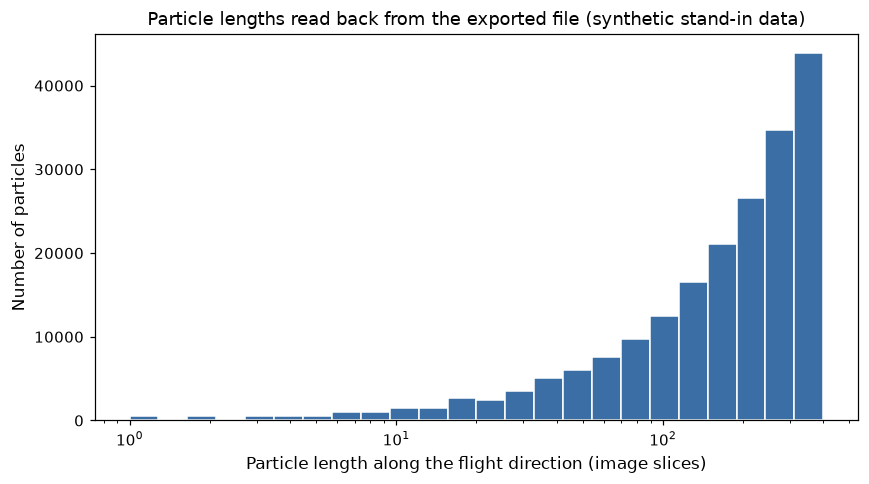

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

with xr.open_dataset(OUT) as ds:
    ds = ds.load()
print(ds)

# image_length: the particle's extent along the flight direction, in image slices.
length = ds["image_length"].values
length = length[length > 0]
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.logspace(np.log10(length.min()), np.log10(length.max() + 1), 25)
ax.hist(length, bins=bins, color="#3b6ea5", edgecolor="white")
ax.set_xscale("log")
ax.set_xlabel("Particle length along the flight direction (image slices)", fontsize=11)
ax.set_ylabel("Number of particles", fontsize=11)
ax.tick_params(labelsize=10)
ax.set_title("Particle lengths read back from the exported file (synthetic stand-in data)", fontsize=12)
fig.tight_layout()
plt.show()

*Figure 1. Particle lengths read back from the exported file with xarray. This is the variable the export narrowed to an integer type; it reads back as ordinary values with no special handling. Most stand-in particles are between 100 and 400 slices long.*

## The file explains itself

Every variable records the dtype it came from, whether it is lossless, and the reason for its
plan; the file records whether *everything* was lossless. A reader six months later does
not have to re-derive any of it, which is the same instinct behind the `.call` sidecars the
port writes beside its own output.

In [8]:
with netCDF4.Dataset(OUT) as ds:
    print("file-level:")
    for a in ds.ncattrs():
        print(f"  {a} = {ds.getncattr(a)}")
    name = next(iter(ds.variables))
    print(f"\nvariable '{name}':")
    for a in ds[name].ncattrs():
        print(f"  {a} = {ds[name].getncattr(a)}")

file-level:
  arrayprobe_arco_export = derived from a bug-for-bug faithful arrayprobe output; the source file is authoritative and unmodified
  arrayprobe_source_file = proc_example.nc
  arrayprobe_all_lossless = true

variable 'image_length':
  arrayprobe_source_dtype = float64
  arrayprobe_lossless = true
  arrayprobe_plan = every value integral in [1, 399]; i2 holds them exactly


## Why chunking is the point, more than size

The compression ratio is the headline, but the property that makes the file *analysis-ready*
is chunked storage. A reader asking for one second decompresses the chunks it touches and
leaves the rest alone — which is what makes a file usable over a network or from object
storage. In NETCDF3 the same request walks the whole variable.

In [9]:
with netCDF4.Dataset(OUT) as ds:
    for name, var in ds.variables.items():
        print(f"{name:20s} chunking={var.chunking()}  filters={var.filters()}")

image_length         chunking=[200000]  filters={'zlib': True, 'szip': False, 'zstd': False, 'bzip2': False, 'blosc': False, 'shuffle': True, 'complevel': 4, 'fletcher32': False}
image_diam_minR      chunking=[200000]  filters={'zlib': True, 'szip': False, 'zstd': False, 'bzip2': False, 'blosc': False, 'shuffle': False, 'complevel': 4, 'fletcher32': False}
particle_time        chunking=[200000]  filters={'zlib': True, 'szip': False, 'zstd': False, 'bzip2': False, 'blosc': False, 'shuffle': False, 'complevel': 4, 'fletcher32': False}


## Lossy floats: available, off by default, and measured when used

`float32` is an option and it is **not** the default, because the measurement does not support
it: 23.5 % of baseline against 24.9 % for lossless `float64` + zlib. A 1.4-point gain is not
worth discarding mantissa bits in a package whose entire claim is fidelity.

When you do ask for it, the **maximum relative error actually introduced is measured per
variable and written into the file** rather than described as "float32 precision".

In [10]:
lossy = SOURCE.with_suffix(".arco-lossy.nc")
plans = export(SOURCE, lossy, lossy_floats=True)

for p in plans:
    if not p.lossless:
        print(f"{p.name:20s} max relative error = {p.max_rel_error:.3e}")
print(f"\n{lossy.stat().st_size / 1e6:.2f} MB "
      f"({100 * lossy.stat().st_size / SOURCE.stat().st_size:.1f} % of the original)")

image_diam_minR      max relative error = 5.953e-08

1.61 MB (33.6 % of the original)


## What this is not

**It is not Zarr.** Zarr's directory-of-chunks layout makes chunks independently addressable
as objects, which is what enables true cloud-native access. It also needs `zarr`, `xarray` and
`dask` — three dependencies this package has so far added none of. It would **not** improve the
compression ratio: the same codecs on the same chunks. Revisit it when the data needs to be
*served*, not when it needs to be smaller.

**It is not part of the port.** `arrayprobe` cannot write this format without giving up the
byte-comparability its validation rests on — including NETCDF3's own failure modes, such as the
2 GiB non-record variable cap that makes a large flight fail at exactly the point MATLAB's
would. The export reads faithful output and derives from it.

---

*Source: `enhancements_uiops/src/arrayprobe_enhancements/arco_export.py`; 11 tests in
`enhancements_uiops/tests/test_arco_export.py`. The measured figures quoted here come from
`enhancements_uiops/README.md`, which records what was measured on real port output and when.*